## Análisis de sensibilidad

Se realizan dos análisis de sensibilidad usando solo el periodo de desarrollo (2015–2018) y las ventanas W1–W3

Respecto a los hiperparámetros, estos se mantienen fijos a los valores seleccionados en el notebook anterior, evaluando así los modelos ridge y random forest.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from modeling import (load_data, make_partitions, make_ridge, make_rf,
                      evaluate_predictions, TARGET, RESULTS_DIR, FIGURES_DIR)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = load_data()
print(df.shape)

(131472, 31)


In [2]:
def run_scenario(partitions, model_name, factory, scenario, **kwargs):
    rows = []
    for window, p in partitions.items():
        model, feats = factory(**kwargs)
        t0 = time.perf_counter()
        model.fit(p["train"][feats], p["train"][TARGET])
        pred = model.predict(p["validation"][feats])
        res = evaluate_predictions(p["train"], p["validation"], pred, model_name, window)
        res["scenario"] = scenario
        res["n_train"] = len(p["train"])
        res["fit_seconds"] = time.perf_counter() - t0
        rows.append(res)
    return pd.concat(rows, ignore_index=True)

## 1. Codificación del calendario

Una de las principales consideraciones a la hora de realizar la predicción de la demanda eléctrica con el paso de los días u horas es la forma de codificación con la cual se representan las variables del calendario. Con esto es que entonces aplicamos un análisis de sensibilidad para evaluar el impacto de una codificación con las variables de la base como variables dummy y una codificación cíclica con las variables de la base transformadas a su seno y coseno.

- Test base: `target_hour`, `target_day` y `target_month` como variables dummy.
- Alternativa: cada variable se reemplaza por su seno y coseno.

Considerando esto, un punto a tener en cuenta es que la transformación seno/coseno es de tipo determinística (no estima parámetros), por lo que no introduce fugas de información.

In [3]:
partitions = make_partitions(df)

sens_a = pd.concat([
    run_scenario(partitions, "Ridge", make_ridge, "Dummy", calendar="dummy"),
    run_scenario(partitions, "Ridge", make_ridge, "Cíclico", calendar="cyclic"),
    run_scenario(partitions, "Random Forest", make_rf, "Dummy", calendar="dummy"),
    run_scenario(partitions, "Random Forest", make_rf, "Cíclico", calendar="cyclic"),
], ignore_index=True)

sens_a_macro = (sens_a[sens_a.country == "Macro"]
                .pivot_table(index=["model", "scenario"], columns="window", values="NMAE"))
sens_a_macro["Mean NMAE"] = sens_a_macro[["W1", "W2", "W3"]].mean(axis=1)
sens_a_macro["SD NMAE"] = sens_a_macro[["W1", "W2", "W3"]].std(axis=1)
sens_a_macro.round(5)

window                       W1       W2       W3  Mean NMAE  SD NMAE
model         scenario                                               
Random Forest Cíclico   0.02756  0.02751  0.02629    0.02712  0.00072
              Dummy     0.02880  0.02860  0.02724    0.02821  0.00085
Ridge         Cíclico   0.04667  0.04719  0.04867    0.04751  0.00104
              Dummy     0.04169  0.04275  0.04402    0.04282  0.00117

In [4]:
sens_a_country = (sens_a[sens_a.country != "Macro"]
                  .groupby(["model", "scenario", "country"])["NMAE"].mean()
                  .unstack("country"))
sens_a_country.round(5)

country                      DE       ES       FR
model         scenario                           
Random Forest Cíclico   0.02613  0.02364  0.03159
              Dummy     0.02677  0.02495  0.03291
Ridge         Cíclico   0.04646  0.04667  0.04940
              Dummy     0.04196  0.04267  0.04383

Estos resultados sugieren que la codificación cíclica es más adecuada para Random Forest en este caso. Al representar cada variable periódica mediante seno y coseno, se conserva la continuidad del calendario: las 23:00 y las 00:00, así como diciembre y enero, quedan próximas en la representación. Esto proporciona al modelo una estructura compacta y coherente que puede combinar con relaciones no lineales e interacciones mediante sus particiones.

En cambio, la codificación cíclica perjudica a Ridge porque, al ser un modelo lineal, los coeficientes asociados al seno y al coseno imponen una variación sutil del efecto de las horas o mensuales, siendo demasiado restrictiva para representar los picos y valles irregulares de una demanda real. A partir de esto es que entonces las variables dummy ofrecen una mayor flexibilidad ya que permiten estimar un efecto independiente para cada categoría.

## 2. Longitud de la historia de entrenamiento

Como ya vimos que la codificación es un factor importante a la hora de modelar procesos temporales como la demanda eléctrica, otro factor que es interesante a considerar es la longitud de la historia del entrenamiento, por lo que para esta ocasión es que se realizó una comparativa entre dos esquemas de entrenamiento:

- Test base: ventana creciente (W1: 2015; W2: 2015–2016; W3: 2015–2017).
- Alternativa: solo el año inmediatamente anterior al origen de validación.

Dado que W1 cumple con ambos esquemas es que entonces la comparación informativa se hace con W2 y W3.

In [5]:
partitions_1y = make_partitions(df, train_years=1)
for w in partitions_1y:
    print(w, "creciente:", len(partitions[w]["train"]), "| último año:", len(partitions_1y[w]["train"]))

sens_b = pd.concat([
    sens_a[(sens_a.scenario == "Dummy")].assign(scenario="Creciente"),
    run_scenario(partitions_1y, "Ridge", make_ridge, "Último año"),
    run_scenario(partitions_1y, "Random Forest", make_rf, "Último año"),
], ignore_index=True)

sens_b_macro = (sens_b[sens_b.country == "Macro"]
                .pivot_table(index=["model", "scenario"], columns="window", values="NMAE"))
sens_b_macro["Mean W2-W3"] = sens_b_macro[["W2", "W3"]].mean(axis=1)
sens_b_macro.round(5)

W1 creciente: 25484 | último año: 25484
W2 creciente: 51836 | último año: 26280
W3 creciente: 77923 | último año: 26015


window                         W1       W2       W3  Mean W2-W3
model         scenario                                         
Random Forest Creciente   0.02880  0.02860  0.02724     0.02792
              Último año  0.02880  0.03087  0.02962     0.03024
Ridge         Creciente   0.04169  0.04275  0.04402     0.04339
              Último año  0.04169  0.04271  0.04423     0.04347

In [6]:
sens_b_country = (sens_b[(sens_b.country != "Macro") & (sens_b.window != "W1")]
                  .groupby(["model", "scenario", "country"])["NMAE"].mean()
                  .unstack("country"))
sens_b_country.round(5)

country                        DE       ES       FR
model         scenario                             
Random Forest Creciente   0.02711  0.02414  0.03251
              Último año  0.02789  0.02613  0.03671
Ridge         Creciente   0.04249  0.04364  0.04403
              Último año  0.04316  0.04290  0.04435

Con estos resultados se puede observar que la longitud de la historia de entrenamiento tiene un impacto significativo para aquellos modelos que son capaces de capturar relaciones no lineales, como Random Forest. La razón detrás de estos resultados es que al tener una mayor cantidad de datos de entrenamiento, el modelo logra aprender patrones mucho más complejos y robustos que le permiten así generalizar mejor a nuevos datos. 

Respecto al modelo ridge, se observa que la longitud no tiene impacto, lo que se traduce en que sus capacidades de aprendizaje son limitadas.

# Export


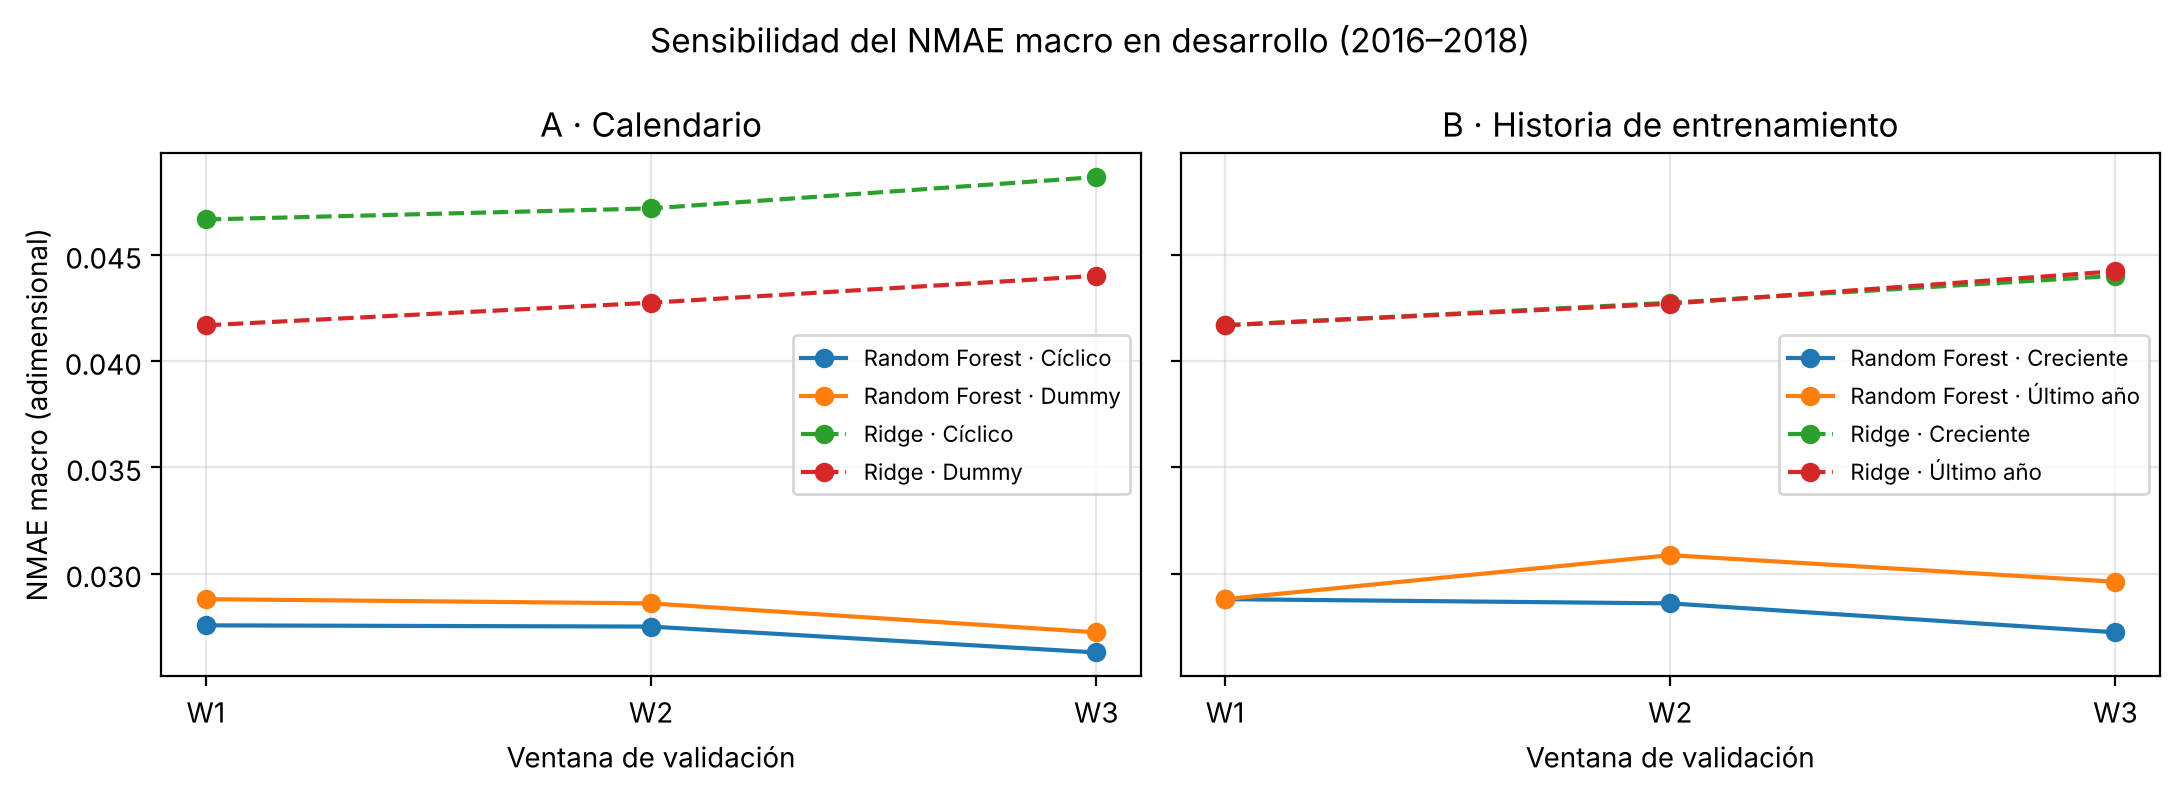

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, data, title in [
    (axes[0], sens_a, "A · Calendario"),
    (axes[1], sens_b, "B · Historia de entrenamiento"),
]:
    m = data[data.country == "Macro"]
    for (model, scen), g in m.groupby(["model", "scenario"]):
        g = g.sort_values("window")
        ls = "-" if model == "Random Forest" else "--"
        ax.plot(g["window"], g["NMAE"], marker="o", ls=ls, label=f"{model} · {scen}")
    ax.set_title(title)
    ax.set_xlabel("Ventana de validación")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("NMAE macro (adimensional)")
fig.suptitle("Sensibilidad del NMAE macro en desarrollo (2016–2018)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sensitivity_nmae.png", dpi=150)
plt.show()

In [8]:
sens_all = pd.concat([sens_a.assign(analysis="A_calendar"),
                      sens_b[sens_b.scenario == "Último año"].assign(analysis="B_history")],
                     ignore_index=True)
sens_all.to_csv(RESULTS_DIR / "sensitivity_results.csv", index=False)
print("Guardado:", RESULTS_DIR / "sensitivity_results.csv")

Guardado: /tmp/claude-0/-home-claude/c3c4fad7-7cf5-5826-bba0-b91debdae005/scratchpad/repo/r/results/sensitivity_results.csv
